In [1]:
import importlib
from pathlib import Path
import pandas as pd
from IPython.display import Image as IPImage
import os
import json
import matplotlib.pyplot as plt
import numpy as np

In [2]:
print(Path.cwd())
os.chdir(Path.cwd().parent)
print(Path.cwd())

import utils.visualize_responses as vr
importlib.reload(vr)
from utils.globals import ITEMS_EXP_FILE, LLM_RESULTS_DIR, HUMAN_RESULTS_DIR, OUTPUT_DIR

/Users/olejurgensen_uva/Projects/KidsARC/KidsARC/notebooks
/Users/olejurgensen_uva/Projects/KidsARC/KidsARC


# Human Data

In [3]:
process_df = pd.read_csv(
    os.path.join(HUMAN_RESULTS_DIR, 'process_generation.csv'),
    dtype={'state': 'string'},
)
response_df = pd.read_csv(
    os.path.join(HUMAN_RESULTS_DIR, 'kidsarc_generation.csv'),
    dtype={'response': 'string'},
)
summary_df = pd.read_csv(os.path.join(HUMAN_RESULTS_DIR, 'generation_summary.csv'))

## Descriptives

In [9]:
age_group_dict = {
    '3-5': (3, 5),
    '6-8': (6, 8),
    '9-11': (9, 11),
    '12-14': (12, 14),
    '15-17': (15, 17),
    '18-30': (18, 30),
    '31-60': (31, 50),
    '60+': (60, 99),
}

def get_age_group(age):
    for group, (min_age, max_age) in age_group_dict.items():
        if min_age <= age <= max_age:
            return group
    return 'Unknown'

summary_df['age_group'] = summary_df['age'].apply(get_age_group)
summary_df['age_group'] = pd.Categorical(
    summary_df['age_group'],
    categories=age_group_dict.keys(),
    ordered=True,
)

/var/folders/r8/5ntdllmd2cnb49xg7kgsw2sm0000gn/T/ipykernel_75346/3084787824.py:19: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  summary_df['age_group'] = pd.Categorical(


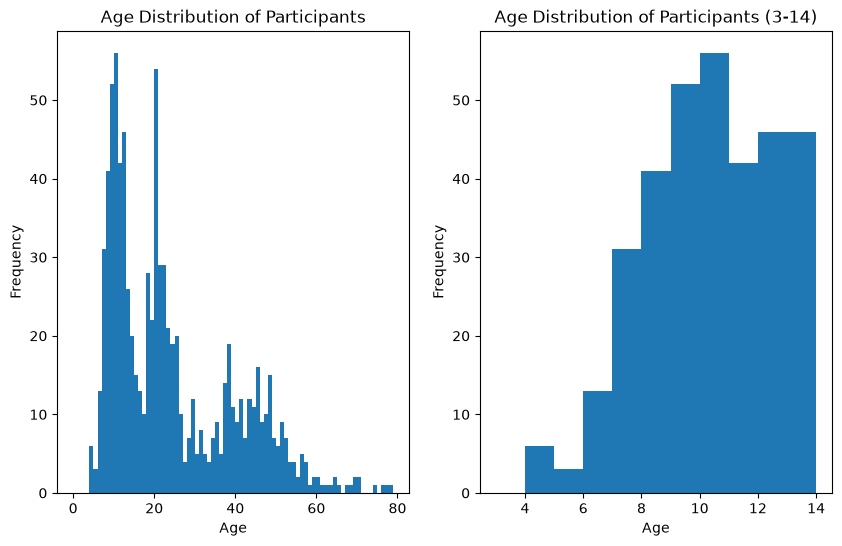

In [10]:
fig, (ax1, ax2) = plt.subplots(figsize=(10, 6), ncols=2)

ax1.hist(summary_df['age'], bins=range(0, 80))
ax1.set_title('Age Distribution of Participants')
ax1.set_xlabel('Age')
ax1.set_ylabel('Frequency')

ax2.hist(summary_df['age'], bins=range(3, 15))
ax2.set_title('Age Distribution of Participants (3-14)')
ax2.set_xlabel('Age')
ax2.set_ylabel('Frequency')

plt.show()

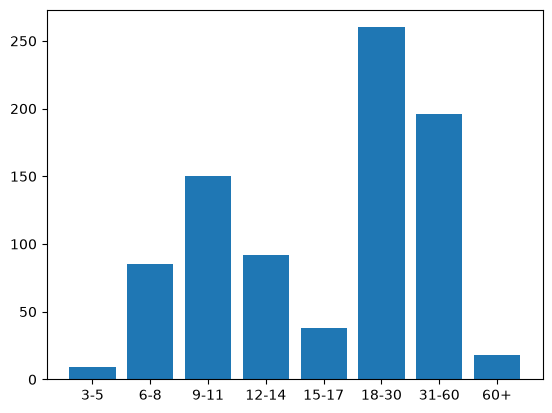

In [11]:
counts = summary_df['age_group'].value_counts().sort_index()
plt.bar(counts.index, counts.values)
plt.show()

In [12]:
summary_df

,participant_id,participant_id_arc,research_study,age,language,n_trials,concept_acc,matrix_acc,duplicate_prop,items,age_group
0,15,212,NEMO2025,12.0,NL,5,1.000000,0.000,0.000,pO7Ghv;aP9mhp;Vu3YJM;w1KvbB;rL3h4H,12-14
1,16,213,NEMO2025,10.0,NL,5,1.000000,0.000,0.000,GiG6QN;S1thE2;H8esRx;NITwty;BGWJeI,9-11
2,24,237,NEMO2025,4.0,EN,5,1.000000,0.000,0.000,zBmElU;gcKe7t;GPAssO;I01GSj;LjIK4w,3-5
3,25,236,NEMO2025,12.0,NL,5,1.000000,0.000,0.000,IsXG7T;F42Xxc;JBB0zi;3lDnft;btNhEm,12-14
4,26,239,NEMO2025,12.0,NL,5,1.000000,0.000,0.000,m4YE3m;bt78zN;IsXG7T;pBTjNa;KsoCTR,12-14
...,...,...,...,...,...,...,...,...,...,...,...
881,2090,1507,WkndvdW2026,23.0,EN,8,1.000000,0.000,0.000,mq5ylD;3wEvCL;VFEQ6f;g3CnCO;UrWSnw;DpP9aA;3lDn...,18-30
882,2093,1510,WkndvdW2026,44.0,EN,7,0.571429,0.000,0.000,RRzrH9;F42Xxc;YQPGJP;N3p7dr;WLWpzN;nTtJUn;vzyqo4,31-60
883,2095,1512,WkndvdW2026,25.0,EN,8,0.750000,0.125,0.125,H6vzjT;kSBTUI;XBoYAo;HqY92i;NITwty;OeqEXb;Gjqi...,18-30
884,2103,1514,WkndvdW2026,11.0,EN,3,0.666667,0.000,0.000,KsoCTR;m4YE3m;TjDWqM,9-11


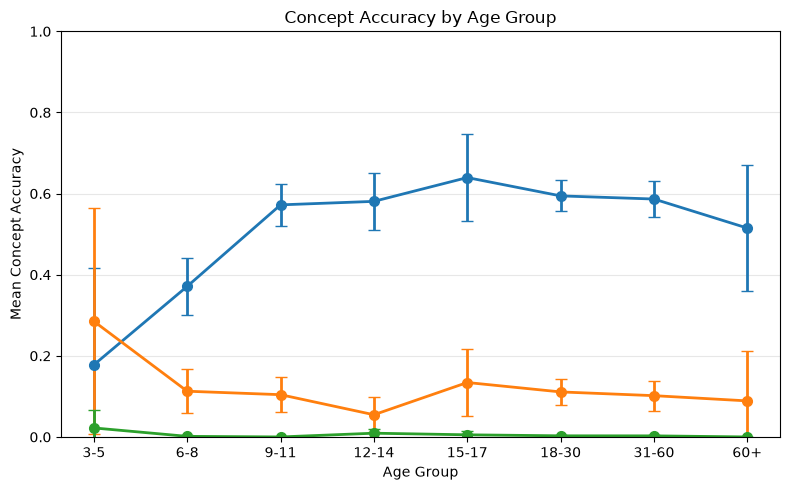

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for acc_type in ['concept_acc', 'duplicate_prop', 'matrix_acc']:

    plot_df = (
        summary_df
        .dropna(subset=['age_group', acc_type])
        .groupby('age_group', observed=True)[acc_type]
        .agg(['mean', 'std', 'count'])
        .reindex(age_group_dict.keys())
    )
    plot_df['ci95'] = 1.96 * plot_df['std'] / np.sqrt(plot_df['count'])
    ax.errorbar(
        plot_df.index,
        plot_df['mean'],
        yerr=plot_df['ci95'],
        fmt='o-',
        capsize=4,
        linewidth=2,
        markersize=7,
    )

ax.set_title('Concept Accuracy by Age Group')
ax.set_xlabel('Age Group')
ax.set_ylabel('Mean Concept Accuracy')
ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

##
Z Process Visualization

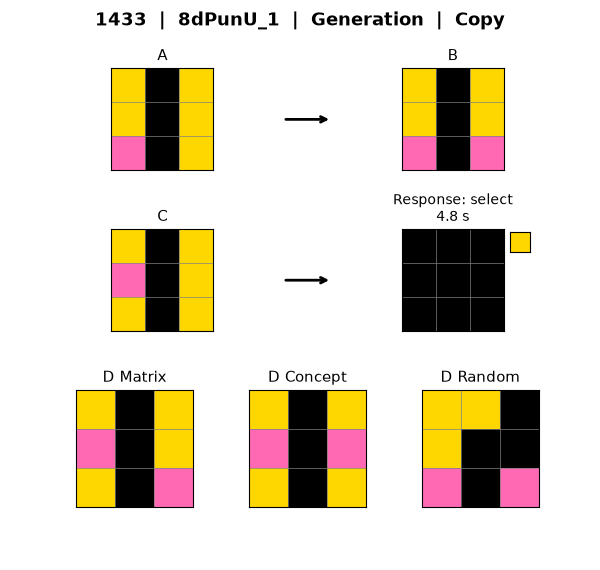

In [14]:
IPImage(filename=vr.process_gif(
    process_df, ITEMS_EXP_FILE, participant=1433, item_id='8dPunU',
    out_path=os.path.join(OUTPUT_DIR, 'process_demo.gif'),
    ))

# LLM Data

In [16]:
llm_response_df = pd.read_csv(
    os.path.join(LLM_RESULTS_DIR, 'scored', 'combined_prelim300.csv'),
    dtype={'parsed': 'string'},
)
llm_response_df.drop(columns=['raw'], inplace=True)

### Functions

In [17]:
CATEGORIES = ["concept", "matrix", "duplicate", "other",
              "unparseable", "truncated", "no_response", "error"]

CAT_COLORS = {
    "concept": "#2b8a3e", "matrix": "#1971c2", "duplicate": "#e8590c",
    "other": "#8242b7", "unparseable": "#ced4da", "truncated": "#d6cc0c",
    "no_response": "#dee2e6", "error": "#c92a2a",
}


def _short(model):
    return model.split("/")[-1]

def plot_performance(scored, sort_by="concept", ax=None):
    """Stacked horizontal bars: share of each response category per model."""
    props = (scored.groupby("model", observed=True)["category"]
                   .value_counts(normalize=True).unstack(fill_value=0))
    props = props.reindex(columns=[c for c in CATEGORIES if c in props.columns])
    props = props.sort_values(sort_by, ascending=True) if sort_by in props else props
    n = scored.groupby("model").size().reindex(props.index)

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.45 * len(props) + 1.2))
    left = np.zeros(len(props))
    for cat in props.columns:
        ax.barh(range(len(props)), props[cat], left=left,
                color=CAT_COLORS[cat], label=cat, edgecolor="white", linewidth=0.5)
        left += props[cat].values
    ax.set_yticks(range(len(props)))
    ax.set_yticklabels([f"{_short(m)}  (n={n[m]})" for m in props.index])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Proportion of responses")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    return ax

## Descriptives

<Axes: xlabel='Proportion of responses'>

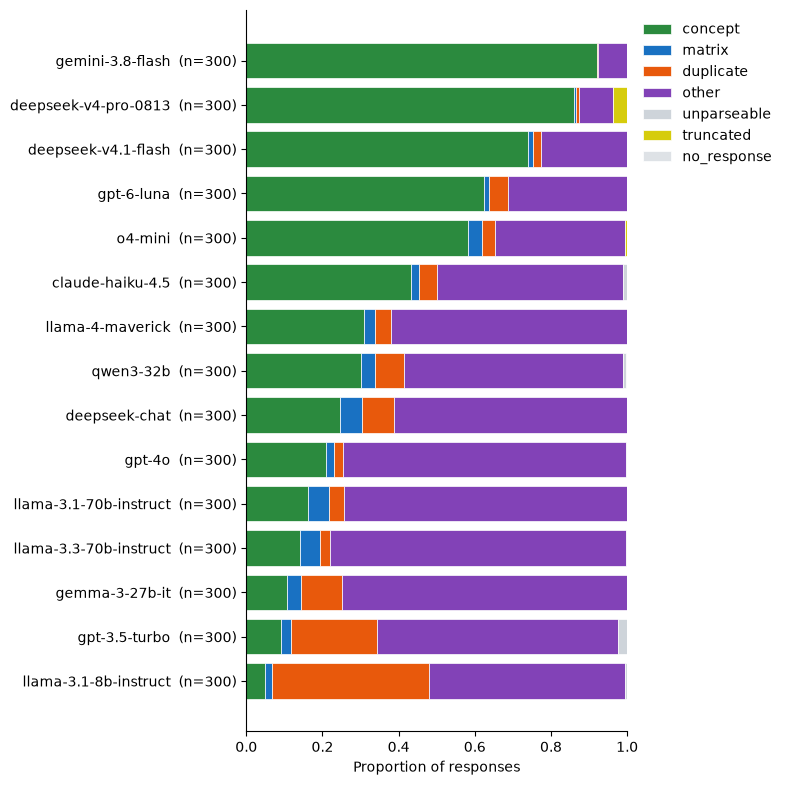

In [18]:
plot_performance(llm_response_df, sort_by="concept")

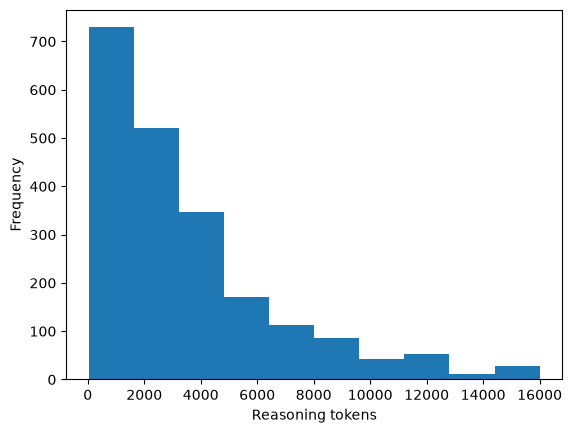

In [19]:
plt.hist(llm_response_df.loc[llm_response_df["reasoning_tokens"] > 0, "reasoning_tokens"])
plt.xlabel("Reasoning tokens")
plt.ylabel("Frequency")
plt.show()


In [ ]:
from matplotlib.patches import Patch

plot_df = llm_response_df.loc[
    llm_response_df["reasoning_tokens"] > 0,
    ["model", "reasoning_tokens", "concept_response"],
].dropna()

model_order = (
    llm_response_df.groupby("model")["concept_response"]
    .mean()
    .sort_values(ascending=False)
    .index
)

models = [model for model in model_order if model in plot_df["model"].unique()]

fig, ax = plt.subplots(figsize=(12, 6))

base_positions = np.arange(len(models)) * 3
correct_positions = base_positions + 1
incorrect_positions = base_positions + 2

for model, correct_position, incorrect_position in zip(
    models, correct_positions, incorrect_positions
):
    model_df = plot_df[plot_df["model"] == model]

    correct = model_df.loc[
        model_df["concept_response"] == 1,
        "reasoning_tokens",
    ]

    incorrect = model_df.loc[
        model_df["concept_response"] == 0,
        "reasoning_tokens",
    ]

    if len(correct) > 0:
        box = ax.boxplot(
            [correct],
            positions=[correct_position],
            widths=0.7,
            patch_artist=True,
            showfliers=False,
        )
        box["boxes"][0].set_facecolor("#2b8a3e")
        box["boxes"][0].set_alpha(0.65)

    if len(incorrect) > 0:
        box = ax.boxplot(
            [incorrect],
            positions=[incorrect_position],
            widths=0.7,
            patch_artist=True,
            showfliers=False,
        )
        box["boxes"][0].set_facecolor("#c92a2a")
        box["boxes"][0].set_alpha(0.65)

ax.set_xticks(base_positions + 1.5)
ax.set_xticklabels(
    [model.split("/")[-1] for model in models],
    rotation=45,
    ha="right",
)

ax.set_xlabel("Model")
ax.set_ylabel("Reasoning tokens")
ax.legend(
    handles=[
        Patch(facecolor="#2b8a3e", alpha=0.65, label="Correct"),
        Patch(facecolor="#c92a2a", alpha=0.65, label="Incorrect"),
    ],
    title="Response",
)

plt.tight_layout()
plt.show()